100%|██████████| 175k/175k [00:00<00:00, 51.4MB/s]

Extracting files...
Dataset loaded successfully!

Total Analyzed Movies: 749


,Series_Title,Released_Year,Primary_Genre,Director,IMDB_Rating,Gross
0,The Shawshank Redemption,1994,Drama,Frank Darabont,9.3,28341469.0
1,The Godfather,1972,Crime,Francis Ford Coppola,9.2,134966411.0
2,The Dark Knight,2008,Action,Christopher Nolan,9.0,534858444.0
3,The Godfather: Part II,1974,Crime,Francis Ford Coppola,9.0,57300000.0
4,12 Angry Men,1957,Crime,Sidney Lumet,9.0,4360000.0


/tmp/ipykernel_994/2868276628.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_movies, x='IMDB_Rating', y='Series_Title', palette='viridis')
/tmp/ipykernel_994/2868276628.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=genre_ratings.head(8), x='IMDB_Rating', y='Primary_Genre', palette='magma')


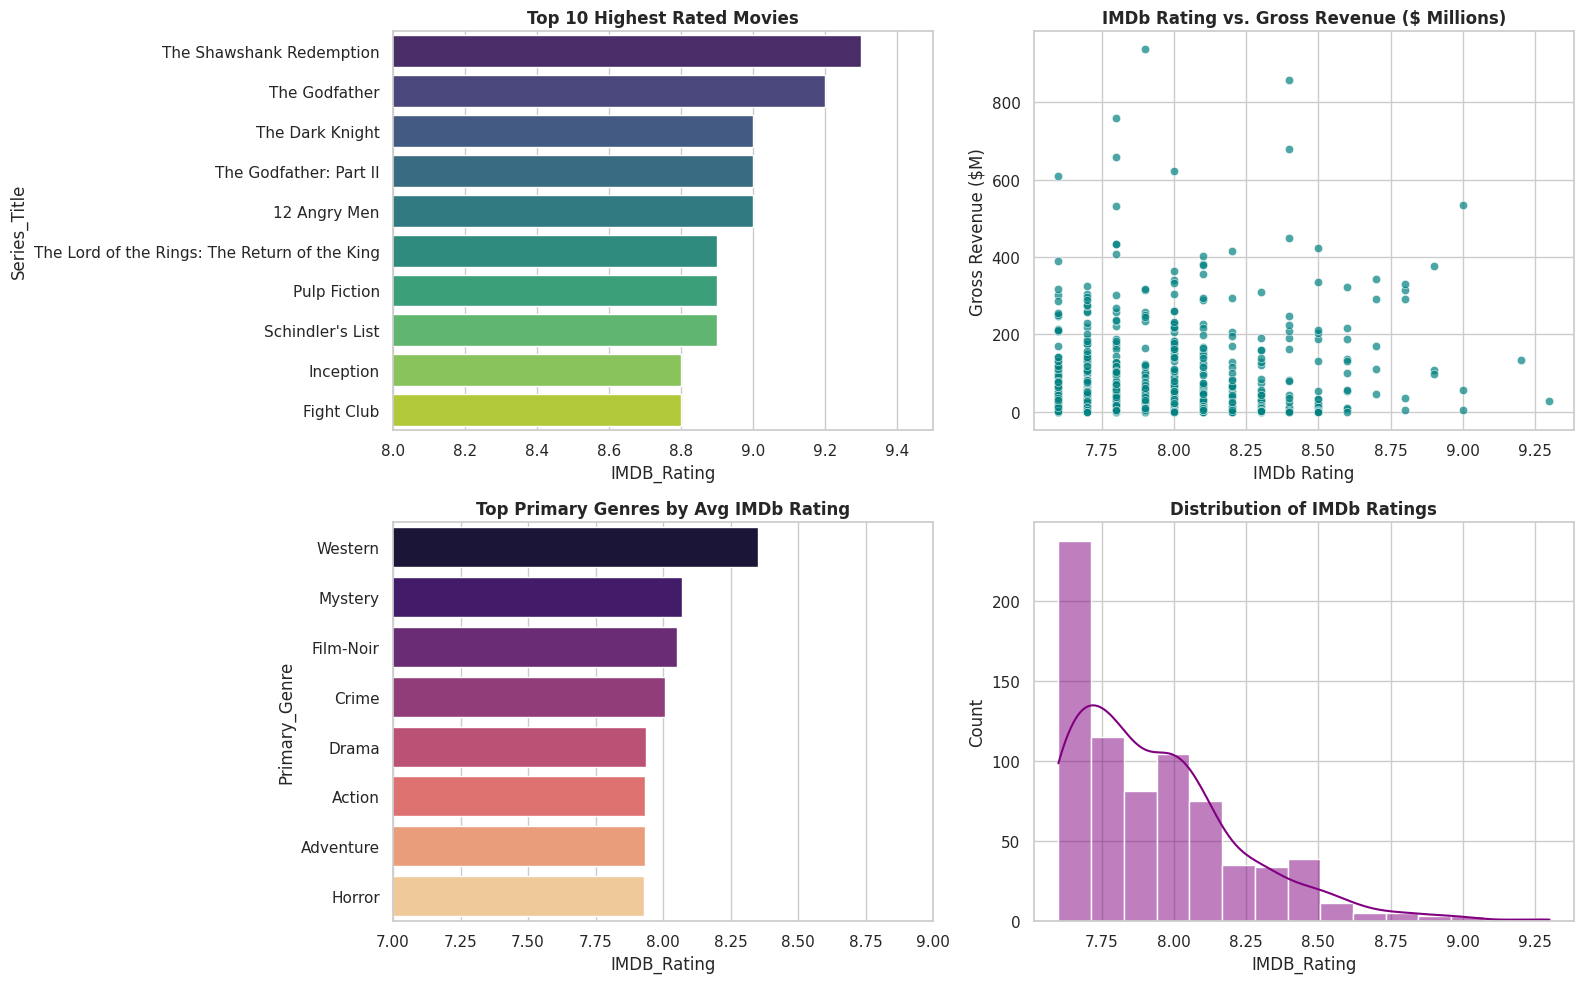

EDA Completed Successfully!


In [3]:
# 1. Install kagglehub to download the official dataset directly
!pip install kagglehub -q

import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 2. Download IMDb Top 1000 dataset via KaggleHub
print("Downloading dataset from Kaggle...")
path = kagglehub.dataset_download("harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows")

# Locate CSV file path and load into DataFrame
csv_path = os.path.join(path, "imdb_top_1000.csv")
df = pd.read_csv(csv_path)
print("Dataset loaded successfully!")

# 3. DATA CLEANING & PREPROCESSING
# Clean 'Gross' revenue column (remove commas and convert to float)
if 'Gross' in df.columns:
    df['Gross'] = df['Gross'].astype(str).str.replace(',', '', regex=False)
    df['Gross'] = pd.to_numeric(df['Gross'], errors='coerce')

# Clean 'Released_Year' column safely
if 'Released_Year' in df.columns:
    df['Released_Year'] = pd.to_numeric(df['Released_Year'], errors='coerce')
    df = df.dropna(subset=['Released_Year'])
    df['Released_Year'] = df['Released_Year'].astype(int)

# Extract Primary Genre
if 'Genre' in df.columns:
    df['Primary_Genre'] = df['Genre'].apply(lambda x: str(x).split(',')[0].strip())

# Clean missing values in critical analysis columns
df = df.dropna(subset=['IMDB_Rating', 'Meta_score', 'Gross'])

print(f"\nTotal Analyzed Movies: {len(df)}")
display(df[['Series_Title', 'Released_Year', 'Primary_Genre', 'Director', 'IMDB_Rating', 'Gross']].head())

# 4. VISUALIZATIONS
plt.figure(figsize=(16, 10))

# Plot 1: Top 10 Highest Rated Movies
plt.subplot(2, 2, 1)
top_movies = df.nlargest(10, 'IMDB_Rating')
sns.barplot(data=top_movies, x='IMDB_Rating', y='Series_Title', palette='viridis')
plt.title('Top 10 Highest Rated Movies', fontweight='bold')
plt.xlim(8.0, 9.5)

# Plot 2: Rating vs Gross Revenue
plt.subplot(2, 2, 2)
sns.scatterplot(data=df, x='IMDB_Rating', y=df['Gross']/1e6, alpha=0.7, color='teal')
plt.title('IMDb Rating vs. Gross Revenue ($ Millions)', fontweight='bold')
plt.xlabel('IMDb Rating')
plt.ylabel('Gross Revenue ($M)')

# Plot 3: Top Primary Genres by Avg Rating
plt.subplot(2, 2, 3)
genre_ratings = df.groupby('Primary_Genre')['IMDB_Rating'].mean().reset_index().sort_values(by='IMDB_Rating', ascending=False)
sns.barplot(data=genre_ratings.head(8), x='IMDB_Rating', y='Primary_Genre', palette='magma')
plt.title('Top Primary Genres by Avg IMDb Rating', fontweight='bold')
plt.xlim(7.0, 9.0)

# Plot 4: Rating Distribution
plt.subplot(2, 2, 4)
sns.histplot(df['IMDB_Rating'], kde=True, color='purple', bins=15)
plt.title('Distribution of IMDb Ratings', fontweight='bold')

plt.tight_layout()
plt.show()

print("EDA Completed Successfully!")

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np

# 1. Feature Selection & One-Hot Encoding for Categorical Genre Data
features = ['Meta_score', 'Gross', 'Primary_Genre']
X = pd.get_dummies(df[features], columns=['Primary_Genre'], drop_first=True)
y = df['IMDB_Rating']

# 2. Split Dataset into Training (80%) and Testing (20%) Sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and Train the Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 4. Predict on Test Data and Evaluate Performance
y_pred = rf_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("--- MACHINE LEARNING MODEL PERFORMANCE ---")
print(f"R² Score: {r2:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

# 5. Display Feature Importances
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop Predictors of IMDb Rating:")
display(importances.head(5))

--- MACHINE LEARNING MODEL PERFORMANCE ---
R² Score: 0.02
Root Mean Squared Error (RMSE): 0.28

Top Predictors of IMDb Rating:


,0
Gross,0.485197
Meta_score,0.335621
Primary_Genre_Crime,0.042469
Primary_Genre_Drama,0.034355
Primary_Genre_Animation,0.023513


In [6]:
# Predict rating for a new movie with Meta_score=85, Gross=$150M, Genre=Action
sample_data = pd.DataFrame([{
    'Meta_score': 85,
    'Gross': 150000000,
    'Primary_Genre': 'Action'
}])

# Align feature columns with training data
sample_encoded = pd.get_dummies(sample_data, columns=['Primary_Genre']).reindex(columns=X.columns, fill_value=0)
predicted_rating = rf_model.predict(sample_encoded)[0]

print(f"Predicted IMDb Rating: {predicted_rating:.2f} / 10")

Predicted IMDb Rating: 7.95 / 10


In [7]:
# Save cleaned dataset and predictions summary
df.to_csv("cleaned_imdb_top_1000.csv", index=False)

# Create a predictions comparison dataframe on test set
results_df = pd.DataFrame({
    'Actual_Rating': y_test,
    'Predicted_Rating': np.round(y_pred, 2)
})
results_df['Difference'] = np.round(np.abs(results_df['Actual_Rating'] - results_df['Predicted_Rating']), 2)
results_df.to_csv("rating_predictions_comparison.csv", index=False)

print("Project CSV deliverables saved successfully!")
display(results_df.head(10))

Project CSV deliverables saved successfully!


,Actual_Rating,Predicted_Rating,Difference
793,7.7,7.87,0.17
508,7.9,7.91,0.01
187,8.2,7.90,0.30
371,8.0,7.86,0.14
430,8.0,7.75,0.25
546,7.9,7.97,0.07
484,7.9,8.02,0.12
225,8.1,7.84,0.26
736,7.7,7.94,0.24
980,7.6,7.90,0.30
